# HDT 7: Clustering y Reducción (hoja corta)

**Ciencia de Datos, Sección A** · Asignada: martes 6 de octubre · **Entrega: martes 13 de octubre, 23:59**

**Nombre:** Milton Orlando Beltrán

Esta hoja es **corta a propósito**: la prioridad de la semana es el Proyecto 2. Cinco ejercicios, casi todo guiado. Completar las celdas marcadas con `# ¿Qué va aquí?`; cada ejercicio trae su verificación comentada. Antes de entregar: **Kernel → Restart & Run All**.

AI: resolver sin AI. Si se usó para entender un concepto, anotarlo en la bitácora del final (no penaliza).

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

## Los datos

Una cafetería con 420 clientes: `gasto` mensual (Q), `visitas` al mes, `ticket` promedio (Q por visita) y `antiguedad` (meses como cliente). Sin etiquetas: nadie sabe cuántos tipos de cliente hay. La celda genera los datos completa.

In [28]:
rng = np.random.default_rng(7)
grupos_reales = [(140, [150, 3, 50, 6]), (140, [450, 10, 45, 18]), (140, [900, 20, 45, 30])]
filas = []
for n, (g, v, tk, a) in grupos_reales:
    filas.append(np.column_stack([
        rng.normal(g, g * 0.18, n).clip(30, 1400),
        rng.normal(v, max(v * 0.2, 1), n).clip(1, 28),
        rng.normal(tk, 8, n).clip(15, 90),
        rng.normal(a, max(a * 0.25, 2), n).clip(1, 48),
    ]))
df = pd.DataFrame(np.vstack(filas).round(1),
                  columns=["gasto", "visitas", "ticket", "antiguedad"])
df = df.sample(frac=1, random_state=7).reset_index(drop=True)
print("clientes:", len(df))
df.head()

clientes: 420


,gasto,visitas,ticket,antiguedad
0,506.7,8.3,53.2,12.6
1,153.5,4.7,60.7,5.7
2,922.6,26.1,48.9,30.0
3,108.7,2.2,49.5,5.7
4,1005.9,21.3,51.4,26.9


### Ejercicio 1 (0.4): escalar y agrupar

Como en la sesión 20: escalar las cuatro columnas con `StandardScaler` (guardar el resultado en `Z`) y correr `KMeans(n_clusters=3, n_init=10, random_state=0)` sobre `Z`. Guardar la etiqueta de cada cliente en `df["grupo"]` e imprimir cuántos clientes hay por grupo.

In [29]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


columnas = ["gasto", "visitas", "ticket", "antiguedad"]
Z = StandardScaler().fit_transform(df[columnas])              # ¿Qué va aquí?
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Z)
df["grupo"] = km.labels_

# imprimir el conteo por grupo
print(df["grupo"].value_counts())

# Verificación (descomentar):
assert sorted(df["grupo"].value_counts().tolist()) == [138, 140, 142]

grupo
2    142
1    140
0    138
Name: count, dtype: int64


### Ejercicio 2 (0.4): el codo

Para k de 1 a 6: correr KMeans (mismos parámetros) y guardar `inertia_` en la lista `inercias`. Graficar contra k y responder en un comentario: ¿dónde está el codo?

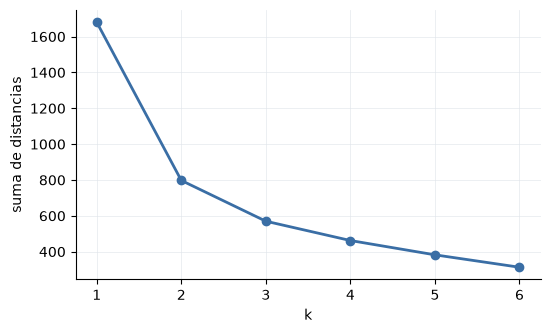

In [30]:
inercias = []
for k in range(1, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    inercias.append(km.inertia_)

# Al completar el loop, descomentar la gráfica:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, 7), inercias, "o-", color=AZUL, lw=2)
ax.set_xlabel("k")
ax.set_ylabel("suma de distancias")
eje_limpio(ax)
plt.show()
# Respuesta: 
# El codo está entre 2 y 3.

# Verificación (descomentar):
assert round(inercias[2]) == 570

### Ejercicio 3 (0.4): el perfil y los nombres

La tabla por grupo: promedio de las cuatro columnas (redondeado a enteros) y el número de clientes. Luego, en el diccionario `nombres`, un nombre de negocio para cada grupo. Una pista de lectura: mirar cuál columna casi NO cambia entre grupos, y decir qué significa en un comentario.

In [31]:
perfil = df.groupby("grupo").mean().round(0)
perfil["clientes"] = df["grupo"].value_counts()

nombres = {0: "fieles", 1: "nuevos de paso", 2: "regulares"}

# Respuesta (la columna plana): 
print(perfil)
# El ticket casi no cambia entre grupos (45, 50 y 46 quetzales por visita).Todos gastan más o menos lo mismo cada vez que llegan
#Para subir el gasto conviene que vengan más seguido, no venderles más por visita.

# Verificación (descomentar):
assert perfil.loc[1, "gasto"] == 145.0 and perfil.loc[1, "visitas"] == 3.0

       gasto  visitas  ticket  antiguedad  clientes
grupo                                              
0      895.0     20.0    45.0        30.0       138
1      145.0      3.0    50.0         5.0       140
2      456.0     10.0    46.0        18.0       142


### Ejercicio 4 (0.5): comprimir con PCA

De cuatro columnas a dos: `PCA(n_components=2)` sobre `Z`, guardar las coordenadas en `Z2` y la fracción de varianza explicada de cada componente. ¿Cuánto capturan entre las dos?

In [32]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)      # ¿Qué va aquí? ajustar sobre Z
Z2 = pca.fit_transform(Z)       # las coordenadas en 2 dimensiones
capturado = sum(pca.explained_variance_ratio_)  # suma de explained_variance_ratio_

print(f"Componente 1: {pca.explained_variance_ratio_[0]:.2f} | componente 2: {pca.explained_variance_ratio_[1]:.2f}")
print(f"Capturado entre las dos: {capturado:.2f}")

# Verificación (descomentar):
assert Z2.shape == (420, 2)
assert round(capturado, 2) == 0.93

Componente 1: 0.69 | componente 2: 0.24
Capturado entre las dos: 0.93


### Ejercicio 5 (0.3): el mapa

Scatter de `Z2` coloreado por grupo (un color por grupo, con `nombres` en la leyenda), con `eje_limpio`. Una frase en un comentario: ¿los grupos se ven separados en el mapa de dos dimensiones?

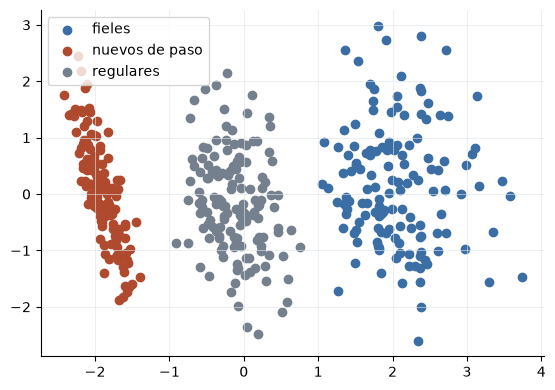

In [33]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
# ¿Qué va aquí? un scatter por grupo, con su nombre en la leyenda
for g, color in zip(nombres.keys(), [AZUL, ROJO, GRIS]):
    ax.scatter(Z2[df["grupo"] == g, 0], Z2[df["grupo"] == g, 1], color=color, label=nombres[g])
ax.legend()
eje_limpio(ax)
plt.show()

# Respuesta: ...

# Verificación (descomentar):
assert len(ax.collections) == 3

## Bitácora de AI (opcional, no penaliza)

Si se usó AI para entender algún concepto, anotar aquí qué se preguntó y qué se entendió. Si no se usó, escribir "No se usó".
- **Ejercicio 4:** usé AI (Claude) para resolver un bug. El código del PCA estaba bien, pero el `assert` de 0.93 fallaba. El problema venía del ejercicio 1: escalaba con `StandardScaler().fit_transform(df)`, todo el DataFrame, y al volver a correr esa celda `df` ya tenía la columna `grupo`, así que `Z` quedó con 5 columnas y el PCA capturaba 0.82 en vez de 0.93. Claude cambió el ejercicio 1 para escalar solo las cuatro columnas (`df[columnas]`) y agregó en el ejercicio 4 los `print` de la varianza de cada componente. Entendí que una celda que depende de cómo está `df` en ese momento puede dar otro resultado si se corre dos veces, y que nombrar las columnas evita que se cuele la etiqueta del clustering en los datos.
- **Ejercicio 5:** usé AI (Claude) para resolver un bug. Escribí `zip(nombres.keys(), AZUL, ROJO, GRIS)` y salía `ValueError: too many values to unpack (expected 2, got 4)`. `zip` recibió cuatro cosas por separado y en cada vuelta armaba una tupla de cuatro: el grupo y una letra de cada color (un texto como `"#3A6EA5"` se recorre letra por letra), pero el `for` solo tenía dos variables, `g` y `color`. Los colores tienen que ir juntos en una lista, `zip(nombres.keys(), [AZUL, ROJO, GRIS])`, para que en cada vuelta salga un par (grupo, color).